# Product Demand and Inventory Intelligence
## Product Segmentation of the BigBasket Catalogue using Unsupervised Machine Learning

| | |
|---|---|
| **Student** | Kunal |
| **Programme** | B.Tech (Artificial Intelligence and Machine Learning), 5th Semester |
| **Institution** | Amity School of Engineering and Technology, Amity University Gurugram |
| **Subject** | Fundamentals of Machine Learning (MLE2503) |
| **Assignment** | Problem Statement 1: Product Demand and Inventory Intelligence |
| **Dataset** | BigBasket Products (27,555 listings, Kaggle) |

### Problem formulation

A large retailer manages thousands of products whose price, discounting and customer response differ widely. Inventory decisions that rely on the product category alone tend to over-stock slow products and under-stock fast ones. The aim of this project is to **discover groups of products that behave alike commercially** and to use those groups to plan stocking and promotions.

### Important note on the data

The BigBasket file is a catalogue snapshot. It contains prices, market prices, brand, category, sub-category, product type, customer rating and a text description. It does **not** contain units sold, stock levels or returns. Demand and inventory behaviour therefore cannot be measured directly and are represented by **proxies** (discount depth, review traction, brand breadth, relative price). Every business interpretation in this notebook is made with this limitation in view, and it is stated again in the conclusions.

### Workflow

1. Load and inspect the data
2. Pre-processing, wrangling and missing values
3. Encoding categorical data
4. Train-test split decision
5. Standardisation and its effect on clustering
6. K-Means, hierarchical clustering, Gaussian mixture and PCA
7. Evaluation, comparison and business interpretation

In [1]:
# ---------------------------------------------------------------
# Imports and global settings
# ---------------------------------------------------------------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings('ignore')
RANDOM_STATE = 42                      # fixed seed so that every result is reproducible
np.random.seed(RANDOM_STATE)
os.makedirs('plots', exist_ok=True)    # all figures are also saved here as PNG files

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = sns.color_palette('colorblind', 10)

def save(fig, name):
    """Save a figure to the plots folder at publication quality."""
    fig.savefig(f'plots/{name}.png', dpi=200, bbox_inches='tight')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## 1. Load the data

The dataset is read with Pandas. The first and last records, the dimensions, the attributes with their data types and the descriptive statistics are displayed, and the attributes are divided into numerical and categorical groups.

In [2]:
# Load the raw file (kept untouched in `raw`; all cleaning is applied to a copy)
raw = pd.read_csv('BigBasket Products.csv')
print('Dimensions (rows, columns):', raw.shape)
print()
print('First five records')
display(raw.head())
print('Last five records')
display(raw.tail())

Dimensions (rows, columns): (27555, 10)

First five records


,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
0,1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
1,2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
2,3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
3,4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
4,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...


Last five records


,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
27550,27551,"Wottagirl! Perfume Spray - Heaven, Classic",Beauty & Hygiene,Fragrances & Deos,Layerr,199.20,249.0,Perfume,3.9,Layerr brings you Wottagirl Classic fragrant b...
27551,27552,Rosemary,Gourmet & World Food,Cooking & Baking Needs,Puramate,67.50,75.0,"Herbs, Seasonings & Rubs",4.0,Puramate rosemary is enough to transform a dis...
27552,27553,Peri-Peri Sweet Potato Chips,Gourmet & World Food,"Snacks, Dry Fruits, Nuts",FabBox,200.00,200.0,Nachos & Chips,3.8,We have taken the richness of Sweet Potatoes (...
27553,27554,Green Tea - Pure Original,Beverages,Tea,Tetley,396.00,495.0,Tea Bags,4.2,"Tetley Green Tea with its refreshing pure, ori..."
27554,27555,United Dreams Go Far Deodorant,Beauty & Hygiene,Men's Grooming,United Colors Of Benetton,214.53,390.0,Men's Deodorants,4.5,The new mens fragrance from the United Dreams ...


In [3]:
# Attributes and data types
info = pd.DataFrame({'dtype': raw.dtypes.astype(str),
                     'non_null': raw.notna().sum(),
                     'unique_values': raw.nunique()})
display(info)

,dtype,non_null,unique_values
index,int64,27555,27555
product,str,27554,23540
category,str,27555,11
sub_category,str,27555,90
brand,str,27554,2313
sale_price,float64,27555,3256
market_price,float64,27555,1348
type,str,27555,426
rating,float64,18929,40
description,str,27440,21944


In [4]:
# Descriptive statistics for numerical and categorical attributes
numeric_cols = raw.select_dtypes(include='number').columns.drop('index').tolist()
categorical_cols = raw.select_dtypes(exclude='number').columns.tolist()
print('Numerical attributes  :', numeric_cols)
print('Categorical attributes:', categorical_cols)
print()
display(raw[numeric_cols].describe().T)
display(raw[['category', 'sub_category', 'brand', 'type']].describe().T)

Numerical attributes  : ['sale_price', 'market_price', 'rating']
Categorical attributes: ['product', 'category', 'sub_category', 'brand', 'type', 'description']



,count,mean,std,min,25%,50%,75%,max
sale_price,27555.0,322.514808,486.263116,2.45,95.0,190.0,359.0,12500.0
market_price,27555.0,382.056664,581.730717,3.00,100.0,220.0,425.0,12500.0
rating,18929.0,3.943410,0.739063,1.00,3.7,4.1,4.3,5.0


,count,unique,top,freq
category,27555,11,Beauty & Hygiene,7867
sub_category,27555,90,Skin Care,2294
brand,27554,2313,Fresho,638
type,27555,426,Face Care,1508


**Observations.** The file holds 27,555 listings and 10 columns. `sale_price`, `market_price` and `rating` are numerical. `category` (11 values), `sub_category` (90), `type` (426) and `brand` (about 2,300) are categorical, and `product` and `description` are free text. The `index` column is only a row identifier and is not used for analysis. Prices are strongly right-skewed (the mean is well above the median), which is typical of retail price data and is dealt with in the outlier section.

## 2. Pre-processing, data wrangling and missing values

### 2.1 Missing, duplicate and inconsistent records

,missing,percent
product,1,0.00
brand,1,0.00
rating,8626,31.30
description,115,0.42


Percentage of products without a rating, by category:


,pct_missing_rating
category,
Snacks & Branded Foods,12.3
"Foodgrains, Oil & Masala",18.0
Baby Care,18.7
Cleaning & Household,21.5
"Bakery, Cakes & Dairy",21.9
Beverages,28.4
"Kitchen, Garden & Pets",29.9
Beauty & Hygiene,30.5
Gourmet & World Food,48.8


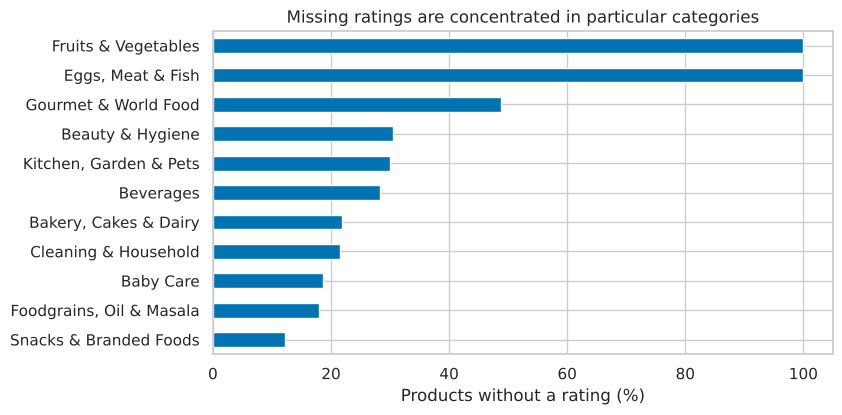

In [5]:
# Missing values
missing = raw.isna().sum().to_frame('missing')
missing['percent'] = (missing['missing'] / len(raw) * 100).round(2)
display(missing[missing['missing'] > 0])

# Where is the rating missing? (by category)
miss_by_cat = raw.groupby('category')['rating'].apply(lambda s: s.isna().mean() * 100).sort_values()
print('Percentage of products without a rating, by category:')
display(miss_by_cat.round(1).to_frame('pct_missing_rating'))

fig, ax = plt.subplots(figsize=(8, 4.2))
miss_by_cat.sort_values().plot.barh(ax=ax, color=PALETTE[0])
ax.set_xlabel('Products without a rating (%)'); ax.set_ylabel('')
ax.set_title('Missing ratings are concentrated in particular categories')
save(fig, '01_missing_ratings_by_category'); plt.show()

In [6]:
# Duplicate records. The `index` column differs for every row, so it is excluded from the comparison.
content_cols = [c for c in raw.columns if c != 'index']
n_dup = raw.duplicated(subset=content_cols).sum()
print('Exact duplicate listings (ignoring the index column):', n_dup)

# Inconsistent records
print('Rows with market_price < sale_price :', (raw['market_price'] < raw['sale_price']).sum())
print('Rows with non-positive prices        :', ((raw['sale_price'] <= 0) | (raw['market_price'] <= 0)).sum())
b = raw['brand'].dropna()
print('Brand names with leading/trailing spaces:', (b != b.str.strip()).sum())
print('Distinct brand spellings before cleaning :', b.nunique())

Exact duplicate listings (ignoring the index column): 354
Rows with market_price < sale_price : 0
Rows with non-positive prices        : 0
Brand names with leading/trailing spaces: 1625
Distinct brand spellings before cleaning : 2313


In [7]:
# ---- Cleaning applied to a working copy ----
df = raw.copy()

# 1. Remove exact duplicates, keeping the first occurrence
df = df.drop_duplicates(subset=content_cols).reset_index(drop=True)

# 2. Drop the single record with no product name (it cannot be identified)
df = df.dropna(subset=['product']).reset_index(drop=True)

# 3. Standardise brand text: trim spaces, collapse repeated spaces, merge case variants
df['brand'] = df['brand'].fillna('Unknown').str.strip().str.replace(r'\s+', ' ', regex=True)
key = df['brand'].str.lower()
canonical = df.groupby(key)['brand'].agg(lambda s: s.value_counts().idxmax())
df['brand'] = key.map(canonical)

# 4. Missing description becomes an empty string
df['description'] = df['description'].fillna('')

print('Rows after cleaning:', len(df), ' (removed', len(raw) - len(df), ')')
print('Distinct brands after cleaning:', df['brand'].nunique())

Rows after cleaning: 27200  (removed 355 )
Distinct brands after cleaning: 2313


**Findings.** There are 354 exact duplicate listings and one listing without a product name, and both were removed (355 rows in all, leaving 27,200). A total of 1,625 brand entries carried leading or trailing spaces and one brand appeared in two letter cases. These were standardised because brand frequency is used later as a feature, and an inconsistent spelling would split one brand into several. The single listing without a brand is labelled 'Unknown'. No record has a market price below its sale price and no price is zero or negative, so no price correction was required.

### 2.2 Imputation of the missing ratings

About 31% of the products have no rating. Two points guide the treatment:

* A missing rating is **informative**. A product that nobody has rated has probably attracted little review activity, so the absence is kept as a separate indicator (`rating_missing`) rather than discarded.
* The rating itself is imputed with the **median rating of the product's sub-category**, which keeps products in line with comparable items. Eggs, Meat and Fish and Fruits and Vegetables have no ratings at all, so the overall median is used as the fallback for them.

The median is preferred over the mean because ratings are skewed towards the upper end of the scale.

In [8]:
df['rating_missing'] = df['rating'].isna().astype(int)          # informative missingness flag

sub_median = df.groupby('sub_category')['rating'].transform('median')
overall_median = df['rating'].median()
df['rating_imp'] = df['rating'].fillna(sub_median).fillna(overall_median)

print('Overall median rating:', overall_median)
print('Remaining missing after imputation:', df['rating_imp'].isna().sum())
display(df[['rating', 'rating_imp']].describe().T)

Overall median rating: 4.1
Remaining missing after imputation: 0


,count,mean,std,min,25%,50%,75%,max
rating,18737.0,3.944420,0.735469,1.0,3.7,4.1,4.3,5.0
rating_imp,27200.0,3.981774,0.617295,1.0,3.9,4.1,4.2,5.0


### 2.3 Feature engineering

Because the raw file has no sales or stock figures, the following features describe commercial behaviour from what is observable.

| Feature | Definition | Business meaning |
|---|---|---|
| `discount_pct` | (market price − sale price) / market price × 100 | Dependence on price promotion |
| `is_discounted` | 1 if `discount_pct` > 0 | Whether the item is promoted at all |
| `log_price` | log(1 + sale price) | Price level, with the skew reduced |
| `price_index` | sale price / median sale price of its sub-category | Premium or economy position within its own sub-category |
| `brand_size` | number of listings of the brand | Breadth and strength of the brand in the assortment |
| `type_size` | number of listings of the same product type | Competition density within the assortment |
| `rating_imp`, `rating_missing` | imputed rating and its missing flag | Customer feedback and review traction |
| `desc_len` | words in the description | Richness of the product listing |

In [9]:
df['discount_pct']  = (df['market_price'] - df['sale_price']) / df['market_price'] * 100
df['is_discounted'] = (df['discount_pct'] > 0).astype(int)

df['brand_size'] = df.groupby('brand')['product'].transform('count')
df['type_size']  = df.groupby(['sub_category', 'type'])['product'].transform('count')
df['price_index'] = df['sale_price'] / df.groupby('sub_category')['sale_price'].transform('median')
df['desc_len']    = df['description'].str.split().str.len()

# Log transforms for right-skewed variables (justified in section 2.4)
df['log_price']       = np.log1p(df['sale_price'])
df['log_brand_size']  = np.log1p(df['brand_size'])
df['log_type_size']   = np.log1p(df['type_size'])
df['log_price_index'] = np.log(df['price_index'])
df['log_desc_len']    = np.log1p(df['desc_len'])

eng = ['discount_pct', 'brand_size', 'type_size', 'price_index', 'desc_len']
display(df[eng].describe().T)
print('Share of products carrying any discount: %.1f%%' % (df['is_discounted'].mean() * 100))

,count,mean,std,min,25%,50%,75%,max
discount_pct,27200.0,11.844758,14.648266,0.000000,0.000000,5.0,20.000000,83.666667
brand_size,27200.0,72.393897,127.839248,1.000000,12.000000,32.0,68.000000,638.000000
type_size,27200.0,215.423309,317.225631,1.000000,55.000000,123.0,218.000000,1453.000000
price_index,27200.0,1.429826,1.674866,0.010033,0.583243,1.0,1.659994,43.321300
desc_len,27200.0,79.417096,61.701214,0.000000,42.000000,62.0,95.250000,734.000000


Share of products carrying any discount: 55.3%


### 2.4 Outlier detection and treatment

Outliers are identified with the 1.5 × IQR rule for the price, discount and brand-size variables. Stock and sales variables are not available in this file, so the outlier review covers the price-related and assortment variables.

,variable,n_outliers,percent,lower_fence,upper_fence,skewness
0,sale_price,2275,8.4,-289.0,735.0,6.22
1,market_price,2100,7.7,-387.5,912.5,5.83
2,discount_pct,435,1.6,-30.0,50.0,1.22
3,brand_size,2338,8.6,-72.0,152.0,3.31
4,type_size,1987,7.3,-189.5,462.5,3.14
5,price_index,1969,7.2,-1.0,3.3,6.31


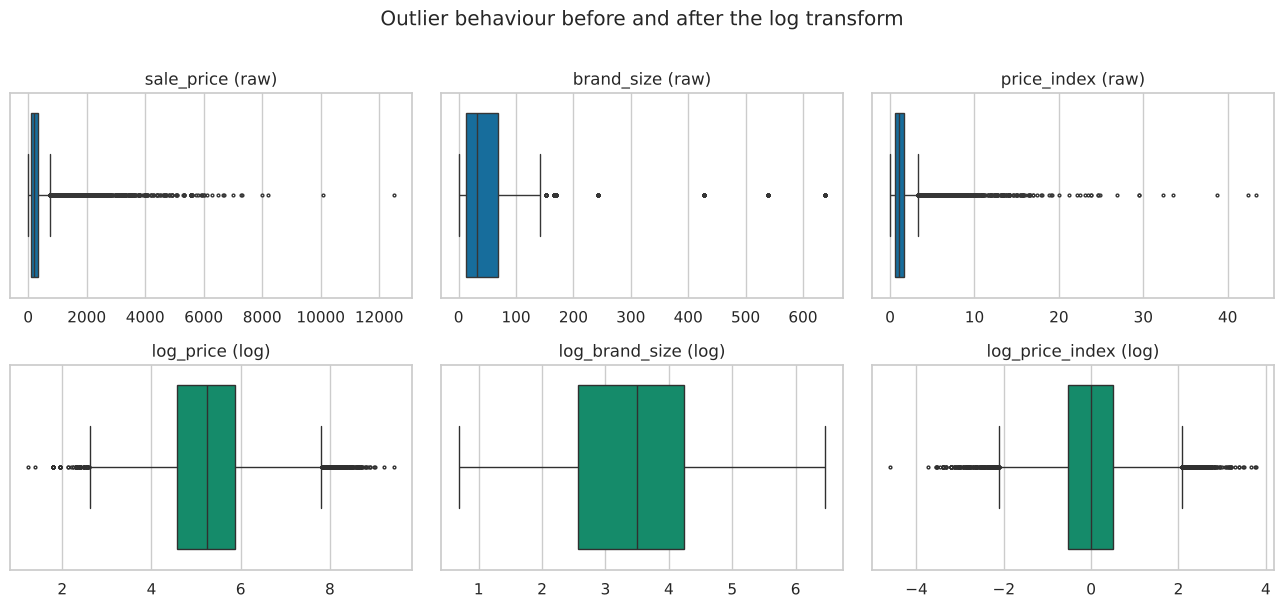

Skewness after log transform:
log_price          0.02
log_brand_size     0.18
log_type_size     -0.19
log_price_index   -0.02
dtype: float64


In [10]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for c in ['sale_price', 'market_price', 'discount_pct', 'brand_size', 'type_size', 'price_index']:
    n, lo, hi = iqr_outliers(df[c])
    rows.append([c, n, round(n / len(df) * 100, 1), round(lo, 1), round(hi, 1), round(df[c].skew(), 2)])
out_tbl = pd.DataFrame(rows, columns=['variable', 'n_outliers', 'percent', 'lower_fence', 'upper_fence', 'skewness'])
display(out_tbl)

# Before and after the log transform
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
pairs = [('sale_price', 'log_price'), ('brand_size', 'log_brand_size'), ('price_index', 'log_price_index')]
for j, (a, b_) in enumerate(pairs):
    sns.boxplot(x=df[a], ax=axes[0, j], color=PALETTE[0], fliersize=2); axes[0, j].set_title(f'{a} (raw)')
    sns.boxplot(x=df[b_], ax=axes[1, j], color=PALETTE[2], fliersize=2); axes[1, j].set_title(f'{b_} (log)')
    axes[0, j].set_xlabel(''); axes[1, j].set_xlabel('')
fig.suptitle('Outlier behaviour before and after the log transform', y=1.01)
fig.tight_layout(); save(fig, '02_outliers_before_after_log'); plt.show()

print('Skewness after log transform:')
print(df[['log_price', 'log_brand_size', 'log_type_size', 'log_price_index']].skew().round(2))

**Decision on outliers: retain, but transform.**

* The high prices (up to ₹12,500) belong to **genuine premium products** such as gas stoves, grooming appliances, imported perfumes, extra-virgin olive oil and bulk pet food, not data-entry errors. Removing them would delete exactly the premium segment that management wants to identify.
* Deleting rows would also be unsafe for K-Means, but leaving the skew untreated lets a handful of extreme values stretch the distance calculation. The log transform compresses the long right tail while keeping every product in the data.
* `discount_pct` is bounded between 0 and 100 and has no impossible values, so it is kept as it is.

### 2.5 Exploratory analysis

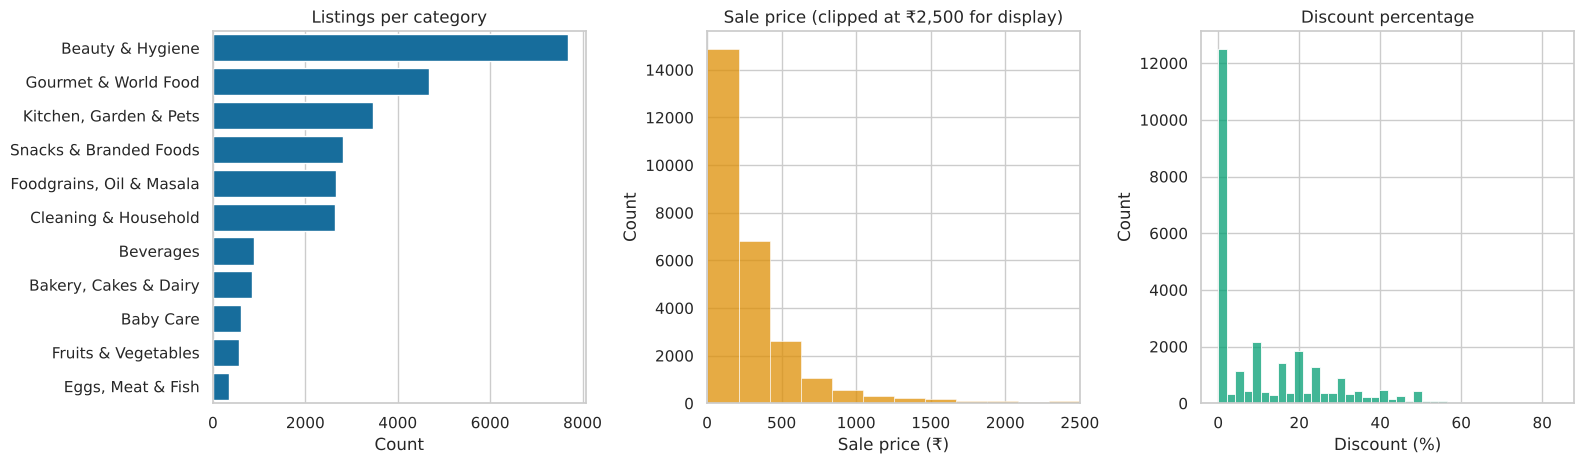

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

order = df['category'].value_counts().index
sns.countplot(y='category', data=df, order=order, ax=axes[0], color=PALETTE[0])
axes[0].set_title('Listings per category'); axes[0].set_ylabel(''); axes[0].set_xlabel('Count')

sns.histplot(df['sale_price'], bins=60, ax=axes[1], color=PALETTE[1])
axes[1].set_xlim(0, 2500); axes[1].set_title('Sale price (clipped at ₹2,500 for display)'); axes[1].set_xlabel('Sale price (₹)')

sns.histplot(df['discount_pct'], bins=40, ax=axes[2], color=PALETTE[2])
axes[2].set_title('Discount percentage'); axes[2].set_xlabel('Discount (%)')
fig.tight_layout(); save(fig, '03_eda_category_price_discount'); plt.show()

,products,median_price,mean_discount_pct,share_discounted,share_unrated
category,,,,,
Beauty & Hygiene,7683,243.60,12.41,0.59,0.30
Gourmet & World Food,4677,240.00,7.86,0.40,0.49
"Kitchen, Garden & Pets",3457,299.00,22.56,0.78,0.29
Snacks & Branded Foods,2810,87.56,6.64,0.38,0.12
"Foodgrains, Oil & Masala",2673,100.00,11.85,0.60,0.18
Cleaning & Household,2650,159.00,10.77,0.56,0.21
Beverages,883,175.00,9.57,0.44,0.28
"Bakery, Cakes & Dairy",850,109.00,7.64,0.49,0.22
Baby Care,610,319.66,5.85,0.36,0.19


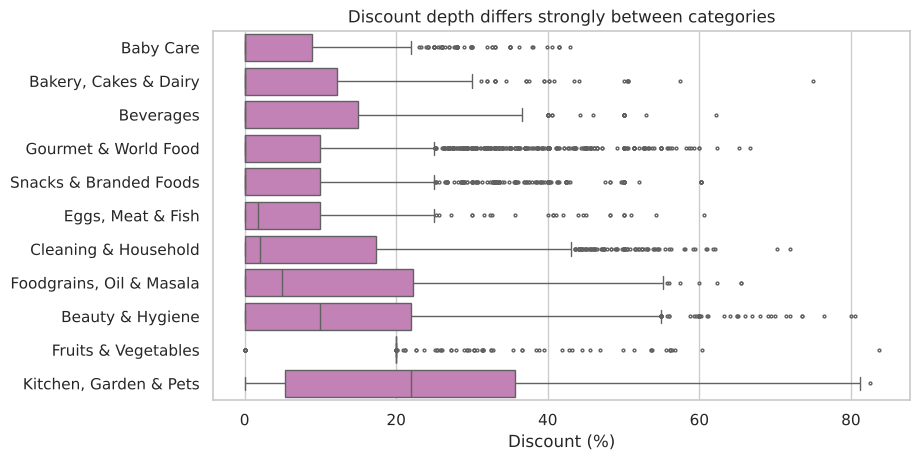

In [12]:
# Category-level commercial behaviour
cat_prof = df.groupby('category').agg(
    products=('product', 'size'),
    median_price=('sale_price', 'median'),
    mean_discount_pct=('discount_pct', 'mean'),
    share_discounted=('is_discounted', 'mean'),
    share_unrated=('rating_missing', 'mean')).round(2).sort_values('products', ascending=False)
display(cat_prof)

fig, ax = plt.subplots(figsize=(9, 4.8))
order = df.groupby('category')['discount_pct'].median().sort_values().index
sns.boxplot(y='category', x='discount_pct', data=df, order=order, ax=ax, color=PALETTE[4], fliersize=2)
ax.set_title('Discount depth differs strongly between categories'); ax.set_ylabel(''); ax.set_xlabel('Discount (%)')
save(fig, '04_discount_by_category'); plt.show()

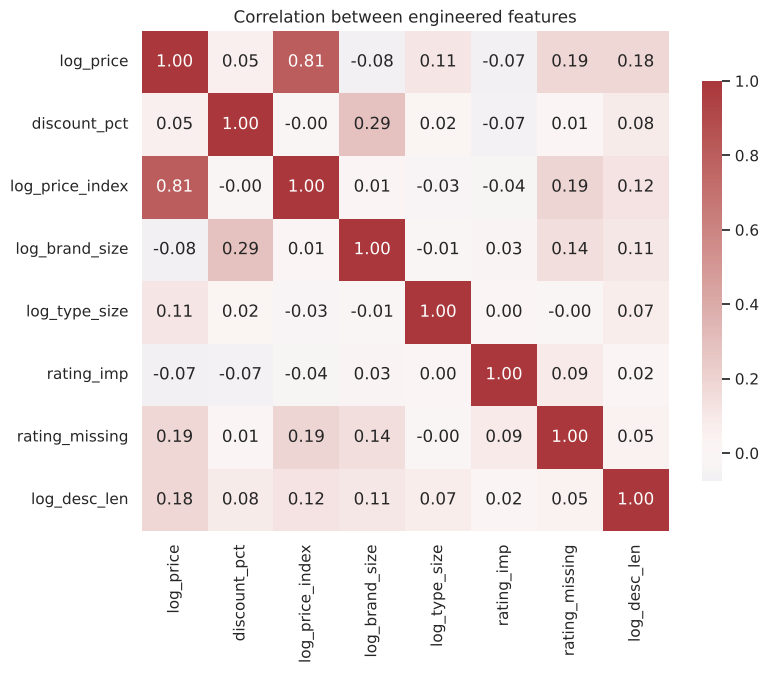

In [13]:
corr_cols = ['log_price', 'discount_pct', 'log_price_index', 'log_brand_size', 'log_type_size',
             'rating_imp', 'rating_missing', 'log_desc_len']
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax, cbar_kws={'shrink': .8})
ax.set_title('Correlation between engineered features')
save(fig, '05_correlation_heatmap'); plt.show()

**Observations.**

* Discounting is shaped by category: Fruits and Vegetables and Kitchen, Garden and Pets are discounted deeply, while Baby Care, Beverages and Snacks are mostly sold at the printed price. A segmentation based on category alone would therefore hide product-level differences inside each category.
* `log_price` and `log_price_index` are highly correlated (about 0.81). Using both would give price double weight in a distance-based method, so only `log_price` is kept in the main model; `log_price_index` is tested in the feature comparison.
* `rating_missing` is positively associated with price, which suggests that the unrated items are comparatively expensive and slow to attract reviews.

## 3. Encode categorical data

| Attribute | Cardinality | Encoding chosen | Reason |
|---|---|---|---|
| `category` | 11 | **One-hot** | Few values and no natural order, so dummy columns avoid implying a false ranking. Used in a comparison model and for profiling. |
| `sub_category` | 90 | **Relative position features** (`price_index`, `type_size`) | One-hot would add 90 sparse columns that dominate Euclidean distance; the useful information is the product's position within its sub-category. |
| `brand` | about 2,300 | **Frequency encoding** (`brand_size`) | One-hot is impractical and label encoding would impose an arbitrary order. Frequency measures how established a brand is, which is commercially meaningful. |
| `type` | 426 | **Frequency encoding** (`type_size`) | Same reasoning as for brand. |

Label encoding is avoided for these attributes because K-Means treats the numbers as distances, and an arbitrary ordering of nominal categories would create false similarity.

In [14]:
# One-hot encoding of the 11 categories (used in the comparison model and for profiling)
cat_dummies = pd.get_dummies(df['category'], prefix='cat', dtype=int)
print('One-hot columns:', cat_dummies.shape[1])
display(cat_dummies.head(3))

# Frequency-encoded columns already created above
display(df[['brand', 'brand_size', 'type', 'type_size']].drop_duplicates('brand').head(5))

One-hot columns: 11


,cat_Baby Care,"cat_Bakery, Cakes & Dairy",cat_Beauty & Hygiene,cat_Beverages,cat_Cleaning & Household,"cat_Eggs, Meat & Fish","cat_Foodgrains, Oil & Masala",cat_Fruits & Vegetables,cat_Gourmet & World Food,"cat_Kitchen, Garden & Pets",cat_Snacks & Branded Foods
0,0,0,1,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1,0
2,0,0,0,0,1,0,0,0,0,0,0


,brand,brand_size,type,type_size
0,Sri Sri Ayurveda,12,Hair Oil & Serum,194
1,Mastercook,58,Water & Fridge Bottles,293
2,Trm,42,Lamp & Lamp Oil,32
3,Nakoda,101,"Laundry, Storage Baskets",141
4,Nivea,87,Bathing Bars & Soaps,374


## 4. Split the dataset

**A conventional train-test split is not required for this task.** Clustering is unsupervised: there is no target variable to predict, so there is no notion of test accuracy that would be corrupted by seeing the data during fitting. The purpose is to describe the structure of the complete catalogue, and holding data back would only reduce the number of products segmented. The complete pre-processed data set is therefore used for clustering.

The reliability of the segmentation is checked in a different way, in section 8: the model is fitted on a random 80% of the products and used to assign the remaining 20%, and the agreement with the full-data model is measured. Stability under resampling is also examined.

## 5. Standardise the data

K-Means and hierarchical clustering are based on Euclidean distance, so a variable measured on a large numerical scale dominates the result. Standardisation (zero mean, unit variance) puts every feature on an equal footing.

### 5.1 Selecting the clustering features

The main model uses five features that describe different aspects of commercial behaviour and are not strongly collinear: `log_price`, `discount_pct`, `log_brand_size`, `rating_imp` and `rating_missing`. Alternative feature sets are compared in section 7.

In [15]:
FEATURES = ['log_price', 'discount_pct', 'log_brand_size', 'rating_imp', 'rating_missing']
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])           # standardised matrix used for clustering
print('Standardised matrix shape:', X.shape)
display(pd.DataFrame(X, columns=FEATURES).describe().loc[['mean', 'std']].round(3))

Standardised matrix shape: (27200, 5)


,log_price,discount_pct,log_brand_size,rating_imp,rating_missing
mean,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


### 5.2 Effect of scaling on clustering

To show why scaling matters, K-Means with K = 5 is fitted on the same features **with and without** standardisation.

Silhouette of the UNSCALED K-Means solution: 0.619
Share of total variance by feature on the original scale (%):


,variance_share_%
log_price,0.49
discount_pct,98.50
log_brand_size,0.74
rating_imp,0.17
rating_missing,0.10


Agreement between unscaled and scaled clusterings (Adjusted Rand Index): 0.257


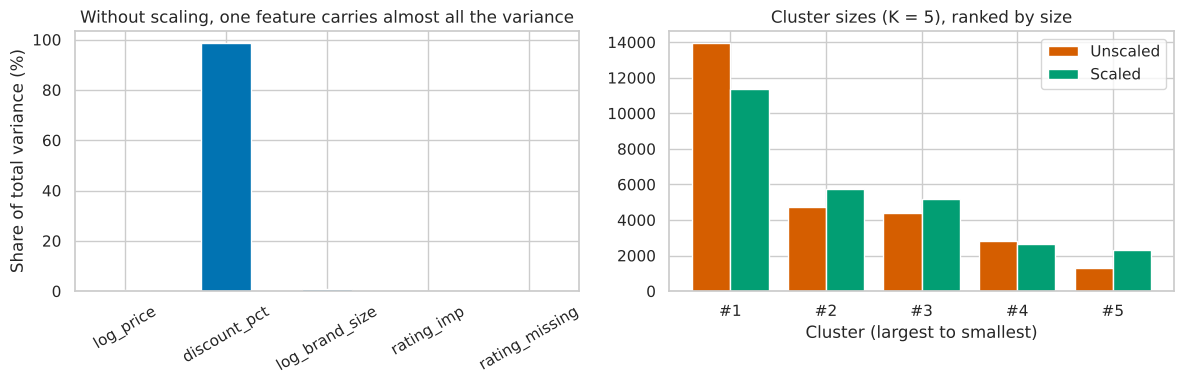

In [16]:
X_raw = df[FEATURES].values
km_raw = KMeans(5, n_init=10, random_state=RANDOM_STATE).fit(X_raw)
km_std = KMeans(5, n_init=10, random_state=RANDOM_STATE).fit(X)

var_share = df[FEATURES].var() / df[FEATURES].var().sum() * 100
ari = adjusted_rand_score(km_raw.labels_, km_std.labels_)
sil_raw = silhouette_score(X_raw, km_raw.labels_, sample_size=10000, random_state=RANDOM_STATE)
print('Silhouette of the UNSCALED K-Means solution: %.3f' % sil_raw)
print('Share of total variance by feature on the original scale (%):')
display(var_share.round(2).to_frame('variance_share_%'))
print('Agreement between unscaled and scaled clusterings (Adjusted Rand Index): %.3f' % ari)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
var_share.plot.bar(ax=axes[0], color=PALETTE[0]); axes[0].set_ylabel('Share of total variance (%)')
axes[0].set_title('Without scaling, one feature carries almost all the variance')
axes[0].tick_params(axis='x', rotation=30)
# Cluster numbers are arbitrary in each run, so the sizes are sorted from largest to smallest before comparing
sz_raw = np.sort(np.bincount(km_raw.labels_))[::-1]; sz_std = np.sort(np.bincount(km_std.labels_))[::-1]
xs = np.arange(5)
axes[1].bar(xs - .2, sz_raw, .4, color=PALETTE[3], label='Unscaled')
axes[1].bar(xs + .2, sz_std, .4, color=PALETTE[2], label='Scaled')
axes[1].set_xticks(xs); axes[1].set_xticklabels([f'#{i+1}' for i in xs])
axes[1].set_title('Cluster sizes (K = 5), ranked by size'); axes[1].set_xlabel('Cluster (largest to smallest)'); axes[1].legend()
fig.tight_layout(); save(fig, '06_effect_of_scaling'); plt.show()

**Interpretation.** Without scaling, `discount_pct` accounts for about 98% of the total variance, so the unscaled clustering is in effect a grouping on discount percentage alone. Price level, brand breadth and review traction contribute almost nothing. The agreement with the scaled clustering is low (Adjusted Rand Index about 0.26), which confirms that scaling changes the segments materially. The silhouette score of the unscaled solution (about 0.62, printed above) looks much better than that of the scaled model (about 0.29), but it is misleading, since it reflects the separation of one dominant variable and not genuine multi-dimensional structure. All later models use the standardised features.

## 6. Machine learning models

### 6.1 K-Means and selection of K (Elbow Method)

K-Means is run for K = 2 to 10 with k-means++ initialisation and ten restarts. Four measures are recorded: inertia (within-cluster sum of squares) for the elbow plot, the silhouette score, the Davies–Bouldin index (lower is better) and the Calinski–Harabasz index (higher is better). The silhouette score on 27,000 points is estimated on a fixed random sample of 10,000 products because the exact calculation needs a full distance matrix.

In [17]:
SIL_SAMPLE = 10000
def internal_metrics(Xm, labels, sil_sample=None):
    """Silhouette, Davies-Bouldin and Calinski-Harabasz for one clustering."""
    return (silhouette_score(Xm, labels, sample_size=sil_sample, random_state=RANDOM_STATE),
            davies_bouldin_score(Xm, labels),
            calinski_harabasz_score(Xm, labels))

ks = range(2, 11)
rows, models = [], {}
for k in ks:
    km = KMeans(k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit(X)
    s, dbi, ch = internal_metrics(X, km.labels_, SIL_SAMPLE)
    rows.append([k, km.inertia_, s, dbi, ch]); models[k] = km
kscan = pd.DataFrame(rows, columns=['K', 'inertia', 'silhouette', 'davies_bouldin', 'calinski_harabasz']).set_index('K')
display(kscan.round(3))

# Automatic elbow: the point with the largest distance from the straight line joining the end points
x = np.array(list(ks), float); y = kscan['inertia'].values
p1, p2 = np.array([x[0], y[0]]), np.array([x[-1], y[-1]])
v = p2 - p1
pts = np.c_[x, y] - p1
d = np.abs(v[0] * pts[:, 1] - v[1] * pts[:, 0]) / np.linalg.norm(v)   # perpendicular distance to the line
elbow_k = int(x[d.argmax()])
print('Elbow detected at K =', elbow_k)

,inertia,silhouette,davies_bouldin,calinski_harabasz
K,,,,
2,107072.013,0.268,1.600,7348.170
3,90123.915,0.261,1.617,6922.216
4,74401.522,0.283,1.287,7505.378
5,65401.987,0.286,1.272,7338.912
6,58135.391,0.252,1.292,7284.562
7,54000.670,0.241,1.239,6882.067
8,50730.302,0.222,1.316,6529.423
9,47563.157,0.245,1.213,6319.722
10,44692.558,0.226,1.241,6172.220


Elbow detected at K = 5


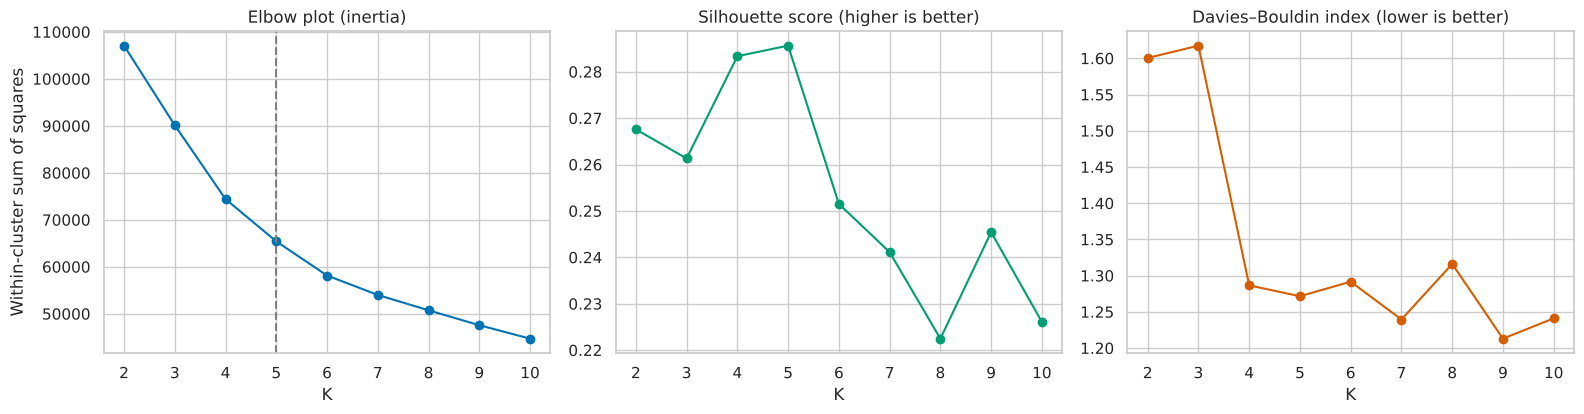

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(kscan.index, kscan['inertia'], 'o-', color=PALETTE[0]); axes[0].axvline(elbow_k, ls='--', color='grey')
axes[0].set_title('Elbow plot (inertia)'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Within-cluster sum of squares')
axes[1].plot(kscan.index, kscan['silhouette'], 'o-', color=PALETTE[2]); axes[1].set_title('Silhouette score (higher is better)'); axes[1].set_xlabel('K')
axes[2].plot(kscan.index, kscan['davies_bouldin'], 'o-', color=PALETTE[3]); axes[2].set_title('Davies–Bouldin index (lower is better)'); axes[2].set_xlabel('K')
for a in axes: a.set_xticks(list(ks))
fig.tight_layout(); save(fig, '07_elbow_silhouette_davies_bouldin'); plt.show()

**Choice of K.** The elbow criterion (largest perpendicular distance from the line joining the end points of the inertia curve) detects K = 5. The silhouette score is highest at K = 5 (0.286) with K = 4 very close (0.283), and it falls for larger K. The Davies–Bouldin index is similar for K = 4 and K = 5 (about 1.29 and 1.27); it is slightly lower for some larger K, but only where the silhouette score has already fallen and the segments become too fragmented to act on. K = 4 and K = 5 are therefore the competing candidates. K = 5 is chosen because it agrees with the elbow and the silhouette peak and because it splits the heavily discounted products into two commercially different groups (those from very large brands with little review activity, and the remainder) that K = 4 would merge. This is a judgement based on both the metrics and the business interpretability, which is the usual approach when no single metric is decisive.

### 6.2 Comparison of feature sets and of the encoding choice

The same K-Means procedure (K = 5) is applied to several feature sets, including a version in which the one-hot encoded category is added to the main features.

,feature_set,n_features,silhouette,davies_bouldin,calinski_harabasz
0,A: price + discount,2,0.376,0.913,20295.495
1,B: A + relative price,3,0.323,0.999,15835.942
2,C: all commercial features,7,0.184,1.548,4869.704
3,D: C + description length,8,0.158,1.718,3986.072
4,G: selected (main model),5,0.286,1.272,7338.912
5,H: selected + one-hot category,16,0.216,1.460,3094.467


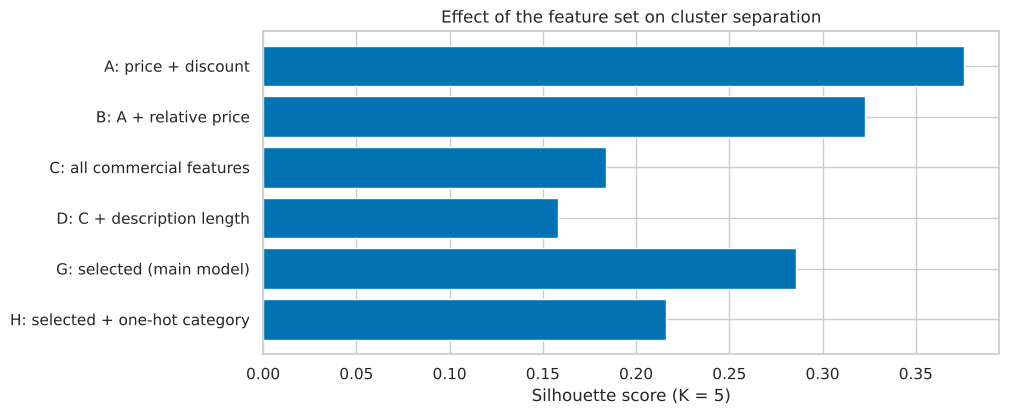

In [19]:
feature_sets = {
    'A: price + discount':                     ['log_price', 'discount_pct'],
    'B: A + relative price':                   ['log_price', 'discount_pct', 'log_price_index'],
    'C: all commercial features':              ['log_price', 'discount_pct', 'log_price_index', 'rating_imp',
                                                'rating_missing', 'log_brand_size', 'log_type_size'],
    'D: C + description length':               ['log_price', 'discount_pct', 'log_price_index', 'rating_imp',
                                                'rating_missing', 'log_brand_size', 'log_type_size', 'log_desc_len'],
    'G: selected (main model)':                FEATURES,
}
rows = []
for name, cols in feature_sets.items():
    Xf = StandardScaler().fit_transform(df[cols])
    km = KMeans(5, n_init=10, random_state=RANDOM_STATE).fit(Xf)
    s, dbi, ch = internal_metrics(Xf, km.labels_, SIL_SAMPLE)
    rows.append([name, len(cols), s, dbi, ch])

# Main features + one-hot category (tests whether adding the encoded category helps)
X_ohe = StandardScaler().fit_transform(pd.concat([df[FEATURES], cat_dummies], axis=1))
km_ohe = KMeans(5, n_init=10, random_state=RANDOM_STATE).fit(X_ohe)
s, dbi, ch = internal_metrics(X_ohe, km_ohe.labels_, SIL_SAMPLE)
rows.append(['H: selected + one-hot category', X_ohe.shape[1], s, dbi, ch])

fs_tbl = pd.DataFrame(rows, columns=['feature_set', 'n_features', 'silhouette', 'davies_bouldin', 'calinski_harabasz']).round(3)
display(fs_tbl)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.barh(fs_tbl['feature_set'], fs_tbl['silhouette'], color=PALETTE[0])
ax.invert_yaxis(); ax.set_xlabel('Silhouette score (K = 5)'); ax.set_title('Effect of the feature set on cluster separation')
save(fig, '08_feature_set_comparison'); plt.show()

**Interpretation.** The two-feature set A has a higher silhouette score (0.376) than the selected set, but this is because only two variables are used and they are easy to separate. It cannot reflect customer feedback, review traction or brand strength, which are exactly the signals needed to discuss demand. Adding further, correlated variables (sets B, C and D) lowers the silhouette score because the extra price-related columns weight price several times over. Adding the one-hot category (set H) makes the solution depend largely on category membership, which is the category-based planning that this project aims to improve on. The selected set G has the best silhouette and Davies–Bouldin values among the sets that represent price, discount, brand and customer feedback together, and it keeps each aspect of behaviour represented once. Silhouette values are not strictly comparable across different feature spaces, so this table is used as supporting evidence together with the interpretability of the resulting segments.

### 6.3 Hierarchical clustering, dendrogram and Gaussian mixture

Agglomerative clustering needs the full pairwise distance matrix, which is impractical for 27,000 products (about 6 GB). A **random sample of 6,000 products** is therefore used for the hierarchical methods. K-Means is refitted on the same sample so that every algorithm is compared on identical data.

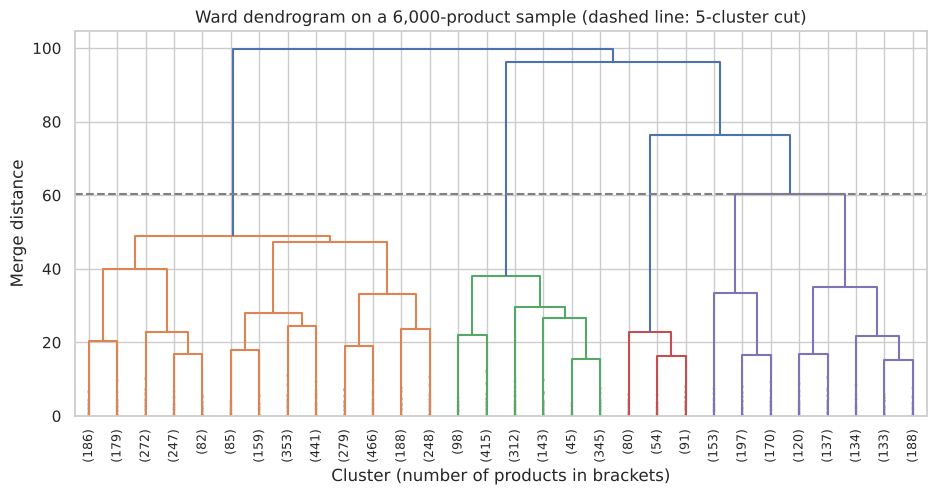

In [20]:
rng = np.random.RandomState(RANDOM_STATE)
samp_idx = rng.choice(len(df), 6000, replace=False)
Xs = X[samp_idx]

# Dendrogram (Ward linkage, truncated to the last 30 merges for readability)
Z = linkage(Xs, method='ward')
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True,
           color_threshold=Z[-4, 2] + 1e-6, ax=ax)
ax.axhline(Z[-4, 2], ls='--', color='grey')
ax.set_title('Ward dendrogram on a 6,000-product sample (dashed line: 5-cluster cut)')
ax.set_xlabel('Cluster (number of products in brackets)'); ax.set_ylabel('Merge distance')
save(fig, '09_dendrogram_ward'); plt.show()

In [21]:
# Candidate solutions evaluated on the same 6,000-product sample
comp = []
def add(name, labels, Xm=Xs):
    s, dbi, ch = internal_metrics(Xm, labels)
    sizes = np.bincount(labels)
    comp.append([name, len(sizes), s, dbi, ch, sizes.min(), sizes.max()])

for k in (4, 5, 6):
    add(f'K-Means, K={k}', KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Xs).labels_)
for k in (4, 5):
    add(f'Hierarchical (Ward), K={k}', AgglomerativeClustering(k, linkage='ward').fit(Xs).labels_)
add('Hierarchical (Average), K=5', AgglomerativeClustering(5, linkage='average').fit(Xs).labels_)
add('Hierarchical (Complete), K=5', AgglomerativeClustering(5, linkage='complete').fit(Xs).labels_)
for k in (4, 5):
    add(f'Gaussian Mixture, K={k}', GaussianMixture(k, covariance_type='full', n_init=3, random_state=RANDOM_STATE).fit(Xs).predict(Xs))

comp_tbl = pd.DataFrame(comp, columns=['solution', 'clusters', 'silhouette', 'davies_bouldin', 'calinski_harabasz',
                                       'smallest_cluster', 'largest_cluster']).round(3)
display(comp_tbl)

,solution,clusters,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster,largest_cluster
0,"K-Means, K=4",4,0.286,1.272,1657.363,582,2824
1,"K-Means, K=5",5,0.291,1.266,1625.365,496,2485
2,"K-Means, K=6",6,0.252,1.290,1609.619,433,1375
3,"Hierarchical (Ward), K=4",4,0.265,1.316,1408.000,225,3185
4,"Hierarchical (Ward), K=5",5,0.266,1.296,1347.482,225,3185
5,"Hierarchical (Average), K=5",5,0.236,0.940,160.332,1,5823
6,"Hierarchical (Complete), K=5",5,0.174,1.590,828.237,264,3803
7,"Gaussian Mixture, K=4",4,0.163,1.858,1070.487,899,2311
8,"Gaussian Mixture, K=5",5,0.114,2.174,905.488,899,1811


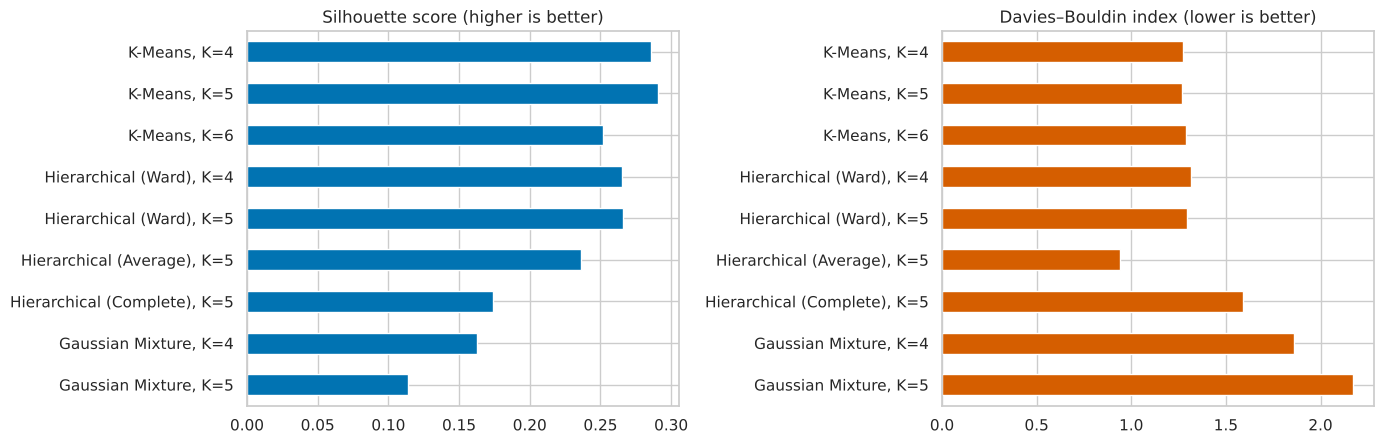

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ct = comp_tbl.set_index('solution')
ct['silhouette'].plot.barh(ax=axes[0], color=PALETTE[0]); axes[0].invert_yaxis()
axes[0].set_title('Silhouette score (higher is better)'); axes[0].set_ylabel('')
ct['davies_bouldin'].plot.barh(ax=axes[1], color=PALETTE[3]); axes[1].invert_yaxis()
axes[1].set_title('Davies–Bouldin index (lower is better)'); axes[1].set_ylabel('')
fig.tight_layout(); save(fig, '10_model_comparison'); plt.show()

**Interpretation.**

* **K-Means (K = 5)** gives the highest silhouette score (0.291) and the lowest Davies–Bouldin index (1.266) among the sensible candidates, and its clusters are reasonably balanced.
* **Ward hierarchical clustering** is slightly weaker (silhouette about 0.27, Davies–Bouldin about 1.30). It is a reasonable second choice, and the dendrogram shows that the merge distance rises steeply over the last few merges (from roughly 50 to 100), which supports a solution of four to five groups.
* **Average linkage** attains a low Davies–Bouldin value only by creating a degenerate cluster containing a single product, so its apparent quality is not useful. **Complete linkage** performs poorly.
* **Gaussian mixture** has much weaker separation (silhouette 0.11 to 0.16), probably because the binary `rating_missing` feature does not follow a Gaussian distribution.

K-Means with K = 5 is therefore selected for the business segmentation.

### 6.4 Principal Component Analysis

PCA is applied for two purposes: to see how many dimensions carry the information, and to visualise the clusters in two dimensions.

Explained variance ratio: [0.267 0.232 0.218 0.16  0.123]  cumulative: [0.267 0.499 0.717 0.877 1.   ]


,PC1,PC2
log_price,0.170,0.696
discount_pct,0.612,-0.276
log_brand_size,0.662,-0.281
rating_imp,-0.000,0.089
rating_missing,0.398,0.594


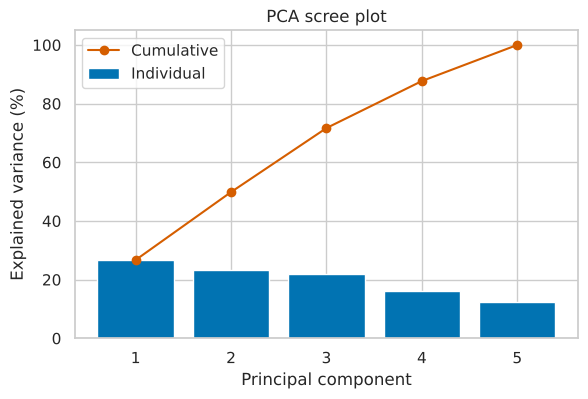

In [23]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca.explained_variance_ratio_
print('Explained variance ratio:', evr.round(3), ' cumulative:', evr.cumsum().round(3))

loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2']).round(3)
display(loadings)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(range(1, len(evr) + 1), evr * 100, color=PALETTE[0], label='Individual')
ax.plot(range(1, len(evr) + 1), evr.cumsum() * 100, 'o-', color=PALETTE[3], label='Cumulative')
ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance (%)'); ax.legend()
ax.set_title('PCA scree plot'); save(fig, '11_pca_scree'); plt.show()

**Interpretation.** The variance is spread almost evenly over the components (the first two explain about 50%). This indicates that the five features carry largely independent information, so dimensionality reduction would discard useful signal. PCA is therefore used only for **visualisation** and not as a pre-processing step for the clustering.

## 7. Final model, evaluation and business interpretation

### 7.1 Final K-Means model (K = 5)

In [24]:
K_FINAL = 5
kmeans = KMeans(K_FINAL, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X)
df['cluster'] = kmeans.labels_

s, dbi, ch = internal_metrics(X, df['cluster'], SIL_SAMPLE)
print(f'Silhouette score          : {s:.3f}')
print(f'Davies-Bouldin index      : {dbi:.3f}')
print(f'Calinski-Harabasz index   : {ch:,.0f}')
print()
sizes = df['cluster'].value_counts().sort_index()
display(pd.DataFrame({'products': sizes, 'share_%': (sizes / len(df) * 100).round(1)}))

Silhouette score          : 0.286
Davies-Bouldin index      : 1.270
Calinski-Harabasz index   : 7,339



,products,share_%
cluster,,
0,11365,41.8
1,5764,21.2
2,2649,9.7
3,2288,8.4
4,5134,18.9


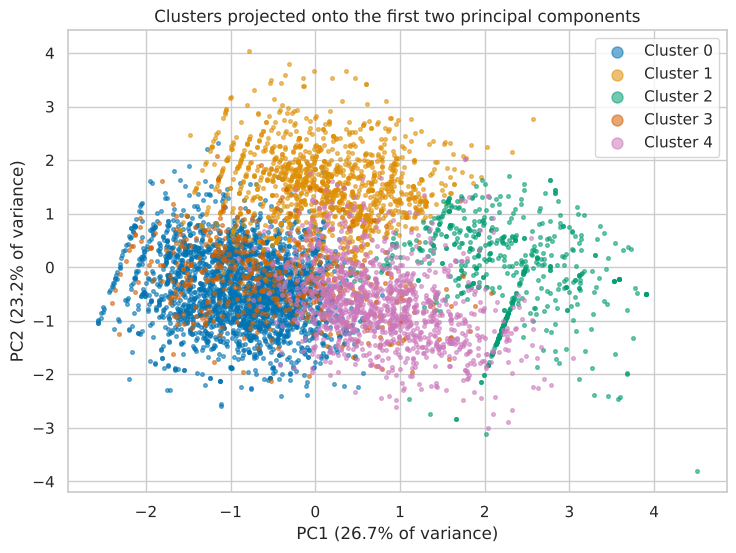

In [25]:
# PCA projection of the clusters (6,000-point sample for a legible plot)
Xp = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
fig, ax = plt.subplots(figsize=(8.5, 6))
for c in range(K_FINAL):
    m = df['cluster'].values[samp_idx] == c
    ax.scatter(Xp[samp_idx][m, 0], Xp[samp_idx][m, 1], s=7, alpha=.55, color=PALETTE[c], label=f'Cluster {c}')
ax.set_xlabel('PC1 (%.1f%% of variance)' % (evr[0] * 100)); ax.set_ylabel('PC2 (%.1f%% of variance)' % (evr[1] * 100))
ax.set_title('Clusters projected onto the first two principal components'); ax.legend(markerscale=3, frameon=True)
save(fig, '12_pca_cluster_plot'); plt.show()

**Reading the plot.** The clusters occupy different regions of the plane (for example, cluster 1 sits towards the top, clusters 2 and 4 towards the right), but they overlap near the centre. This is consistent with the moderate silhouette score and shows that the boundaries between segments are gradual. The straight diagonal line of points in cluster 2 is a group of fresh-produce items from one brand that share nearly identical feature values.

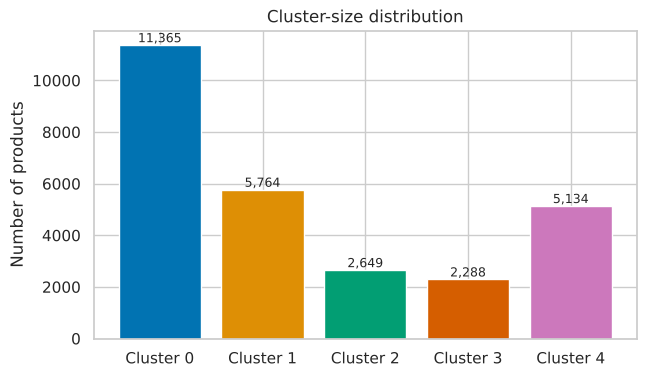

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([f'Cluster {c}' for c in sizes.index], sizes.values, color=[PALETTE[c] for c in sizes.index])
for b_, v in zip(bars, sizes.values): ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Number of products'); ax.set_title('Cluster-size distribution')
save(fig, '13_cluster_sizes'); plt.show()

### 7.2 Cluster profiles

,products,median_price,mean_discount_pct,share_discounted,median_brand_size,share_unrated,mean_rating_rated_only,median_price_index
cluster,,,,,,,,
0,11365,127.50,3.82,0.38,22.0,0.00,4.19,0.83
1,5764,300.00,4.85,0.32,19.0,1.00,4.55,1.34
2,2649,159.00,26.68,0.95,170.0,0.99,4.06,1.00
3,2288,297.25,10.62,0.53,24.0,0.00,2.44,1.29
4,5134,209.00,30.35,1.00,53.0,0.01,4.07,0.98


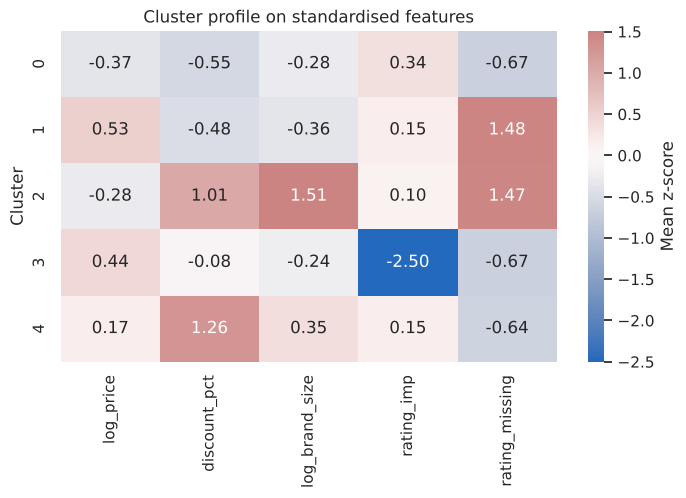

In [27]:
profile = df.groupby('cluster').agg(
    products=('product', 'size'),
    median_price=('sale_price', 'median'),
    mean_discount_pct=('discount_pct', 'mean'),
    share_discounted=('is_discounted', 'mean'),
    median_brand_size=('brand_size', 'median'),
    share_unrated=('rating_missing', 'mean'),
    mean_rating_rated_only=('rating', 'mean'),
    median_price_index=('price_index', 'median')).round(2)
display(profile)

# Standardised profile heat map (mean z-score of each clustering feature)
z = pd.DataFrame(X, columns=FEATURES); z['cluster'] = df['cluster'].values
zprof = z.groupby('cluster').mean()
fig, ax = plt.subplots(figsize=(8, 4.3))
sns.heatmap(zprof, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax, cbar_kws={'label': 'Mean z-score'})
ax.set_title('Cluster profile on standardised features'); ax.set_ylabel('Cluster')
save(fig, '14_cluster_profile_heatmap'); plt.show()

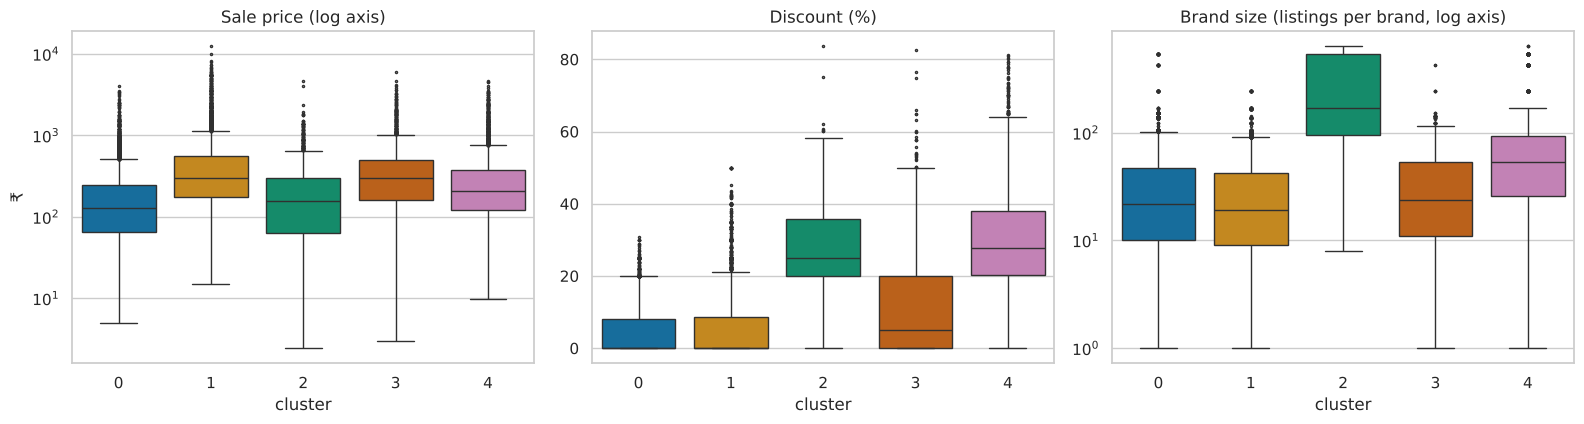

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sns.boxplot(x='cluster', y='sale_price', data=df, ax=axes[0], palette=PALETTE[:K_FINAL], fliersize=1.5)
axes[0].set_yscale('log'); axes[0].set_title('Sale price (log axis)'); axes[0].set_ylabel('₹')
sns.boxplot(x='cluster', y='discount_pct', data=df, ax=axes[1], palette=PALETTE[:K_FINAL], fliersize=1.5)
axes[1].set_title('Discount (%)'); axes[1].set_ylabel('')
sns.boxplot(x='cluster', y='brand_size', data=df, ax=axes[2], palette=PALETTE[:K_FINAL], fliersize=1.5)
axes[2].set_yscale('log'); axes[2].set_title('Brand size (listings per brand, log axis)'); axes[2].set_ylabel('')
fig.tight_layout(); save(fig, '15_cluster_boxplots'); plt.show()

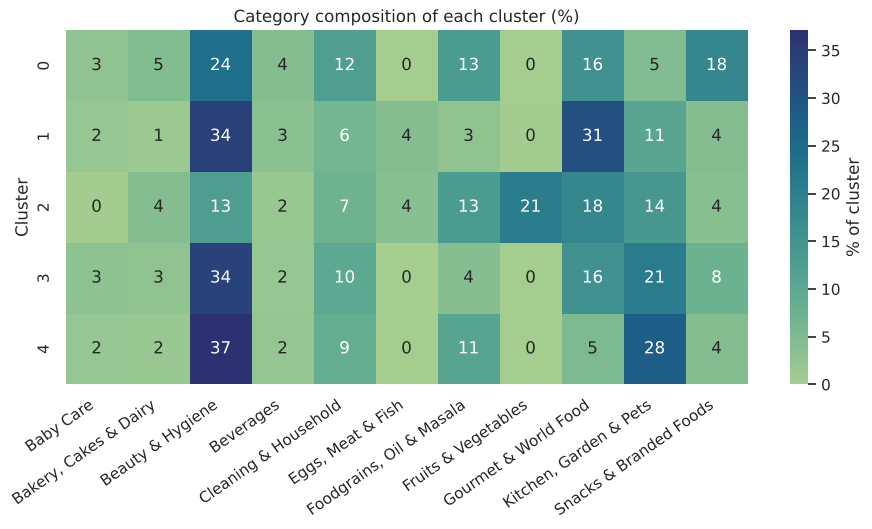

In [29]:
mix = pd.crosstab(df['cluster'], df['category'], normalize='index') * 100
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(mix, annot=True, fmt='.0f', cmap='crest', ax=ax, cbar_kws={'label': '% of cluster'})
ax.set_title('Category composition of each cluster (%)'); ax.set_ylabel('Cluster'); ax.set_xlabel('')
plt.xticks(rotation=35, ha='right')
save(fig, '16_category_mix_by_cluster'); plt.show()

### 7.3 Naming the segments

The segments are given names from their measured profile. The rules below are applied to the profile table, so the labels follow the data and not the numbering of the clusters.

In [30]:
def name_segment(r):
    if r['mean_discount_pct'] >= 20 and r['median_brand_size'] >= 100:
        return 'Large-brand discounted, low review traction'
    if r['mean_discount_pct'] >= 20:
        return 'Promotion-driven'
    if r['share_unrated'] >= 0.8:
        return 'Premium full-price, low review traction'
    if r['mean_rating_rated_only'] < 3.2:
        return 'Low-rated, quality-risk'
    return 'Core everyday value'

profile['segment'] = profile.apply(name_segment, axis=1)
assert profile['segment'].is_unique, 'two clusters received the same name; revise the rules'
df['segment'] = df['cluster'].map(profile['segment'])
display(profile[['products', 'median_price', 'mean_discount_pct', 'median_brand_size', 'share_unrated',
                 'mean_rating_rated_only', 'segment']])

,products,median_price,mean_discount_pct,median_brand_size,share_unrated,mean_rating_rated_only,segment
cluster,,,,,,,
0,11365,127.50,3.82,22.0,0.00,4.19,Core everyday value
1,5764,300.00,4.85,19.0,1.00,4.55,"Premium full-price, low review traction"
2,2649,159.00,26.68,170.0,0.99,4.06,"Large-brand discounted, low review traction"
3,2288,297.25,10.62,24.0,0.00,2.44,"Low-rated, quality-risk"
4,5134,209.00,30.35,53.0,0.01,4.07,Promotion-driven


### 7.4 Business interpretation and strategy

Because the file has no sales or stock data, the segments are interpreted through proxies, and the strategies below are recommendations to be validated against actual sales and stock records.

| Segment | What the data shows | Commercial reading (proxy-based) | Inventory and stocking | Promotion |
|---|---|---|---|---|
| **Core everyday value** | The largest group (42% of products); lowest median price (about ₹128), low discount, well rated, every item has reviews | Probable **fast-moving, high-demand** staples | Keep high safety stock and frequent replenishment; avoid stock-outs; negotiate volume terms | Little need for discounts; use as traffic-builders and bundle anchors |
| **Promotion-driven** | Every item discounted, about 30% on average, median price about ₹209, rated | **Promotion-dependent** demand | Stock to the promotion calendar; build inventory ahead of campaigns and run down afterwards | Plan campaigns and measure uplift; test whether shallower discounts hold sales |
| **Premium full-price, low review traction** | High price (median about ₹300), under 5% discount on average, almost none rated | **Premium, probable slow-moving** | Carry minimal stock and replenish on order or by small batches; protect against ageing | Targeted, not mass, promotion; promote reviews to build trust |
| **Low-rated, quality-risk** | High price (median about ₹297), average rating about 2.4 | Customer dissatisfaction | Reduce stock; review the supplier or quality before reordering | Do not discount to clear until quality is checked; consider delisting |
| **Large-brand discounted, low review traction** | Very broad brands (median 170 listings per brand), average discount about 27%, almost none rated, includes fresh produce | Wide, low-priced assortment with little review activity | Keep lean stock, short shelf-life handling | Brand-level promotions rather than item-level |

## 8. Validation of the segmentation

Since a conventional test set is not used, two checks assess whether the segments are dependable.

1. **Hold-out check.** The scaler and K-Means are fitted on a random 80% of the products. The remaining 20% are assigned to the nearest centroid and compared with the full-data model by the Adjusted Rand Index (ARI).
2. **Bootstrap stability.** K-Means is refitted on ten random 80% subsamples and compared with the full-data labels for the same products.

In [31]:
# 1. Hold-out check
rng = np.random.RandomState(RANDOM_STATE)
perm = rng.permutation(len(df)); cut = int(.8 * len(df))
tr, te = perm[:cut], perm[cut:]
sc_tr = StandardScaler().fit(df.iloc[tr][FEATURES])
km_tr = KMeans(K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(sc_tr.transform(df.iloc[tr][FEATURES]))
pred_te = km_tr.predict(sc_tr.transform(df.iloc[te][FEATURES]))
ari_hold = adjusted_rand_score(df['cluster'].values[te], pred_te)
print('Hold-out agreement with the full model (ARI): %.3f' % ari_hold)

# 2. Bootstrap stability
aris = []
for b_ in range(10):
    ii = rng.choice(len(df), int(.8 * len(df)), replace=False)
    kb = KMeans(K_FINAL, n_init=10, random_state=b_).fit(X[ii])
    aris.append(adjusted_rand_score(df['cluster'].values[ii], kb.labels_))
print('Bootstrap stability (ARI): mean %.3f, std %.3f, min %.3f' % (np.mean(aris), np.std(aris), np.min(aris)))

Hold-out agreement with the full model (ARI): 0.983


Bootstrap stability (ARI): mean 0.987, std 0.006, min 0.974


Values close to 1 show that the same products are grouped together whichever subset is used, so the segmentation is stable and not an artefact of the particular sample.

## 9. Conclusions

1. The catalogue contains five commercially distinct product groups that a category-based view does not reveal. Each group spreads across several categories (section 7.2), so category-wise planning would apply the same treatment to products that behave differently.
2. K-Means with K = 5 on standardised features gave the best internal quality among the models tested (silhouette about 0.29, Davies–Bouldin about 1.27) and was very stable (ARI about 0.98 on the hold-out check and 0.99 under resampling).
3. The silhouette value of about 0.29 indicates **moderate, overlapping structure**, not sharply separated clusters. This is expected for commercial attributes, which vary continuously, and the segments should be used as planning groups and not as rigid classes.
4. Standardisation was essential: without it, one variable determined about 98% of the distance.
5. Outliers were retained and log-transformed, because the expensive products are the genuine premium segment.

### Limitations

* The data has no units sold, stock or return figures. "Fast-moving" and "slow-moving" are inferred from review traction, discount depth and brand breadth, which are indirect. The recommendations must be tested against real sales and inventory data.
* Roughly 31% of ratings are missing and two categories have none, so imputed ratings carry limited information; the separate missing-flag was used to avoid hiding this.
* Hierarchical clustering was run on a 6,000-product sample because of memory limits.

### References

1. MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, 1, 281–297.
2. Arthur, D. and Vassilvitskii, S. (2007). k-means++: the advantages of careful seeding. *Proceedings of the 18th ACM-SIAM Symposium on Discrete Algorithms*, 1027–1035.
3. Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
4. Davies, D. L. and Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, PAMI-1(2), 224–227.
5. Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association*, 58(301), 236–244.
6. Caliński, T. and Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics*, 3(1), 1–27.
7. Hubert, L. and Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2, 193–218.
8. Jolliffe, I. T. and Cadima, J. (2016). Principal component analysis: a review and recent developments. *Philosophical Transactions of the Royal Society A*, 374, 20150202.
9. Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
10. BigBasket Products dataset, Kaggle (27,555 product listings).